# MoveBench: Global Trajectory Map + Coverage Ideas

This notebook:

1. Loads **all studies** under `MOVEBENCH_DATA_ROOT/studies_10ind/` (i.e., the full benchmark dataset root).
2. Builds per-individual trajectory polylines.
3. Saves **static** global plots (PNG) of trajectories and point density.
4. Brainstorms additional ways to visualize dataset **coverage** (space/time/environment).

If you need plotting deps:

```bash
pip install -e ".[apps]"
```

Notes:
- By default, images are written under `pngs/` at the repo root.
- If `cartopy` is installed, the plots include coastlines; otherwise they fall back to a plain lon/lat canvas.
- For very large benchmarks, increase downsampling to keep rendering fast.


In [1]:
from __future__ import annotations

import os
import sys
from pathlib import Path

# --- Repo + data root wiring ---
# If you're not running from repo root, uncomment and set this:
# os.chdir("/path/to/movebench")

# Find repo root by walking upward until we see the package directory.
repo_root = Path.cwd().resolve()
while repo_root != repo_root.parent and not (repo_root / 'movebench').exists():
    repo_root = repo_root.parent
if not (repo_root / 'movebench').exists():
    raise RuntimeError('Could not find repo root (expected a movebench/ directory). Set os.chdir(...) first.')

if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

# If MOVEBENCH_DATA_ROOT isn't configured, default to the repo-local data path
# so Study.list_available() works out-of-the-box for this checkout.
_default_data_root = (repo_root / 'data' / 'movebench').resolve()
if 'MOVEBENCH_DATA_ROOT' not in os.environ and _default_data_root.exists():
    os.environ['MOVEBENCH_DATA_ROOT'] = str(_default_data_root)

print('repo_root:', repo_root)
print('MOVEBENCH_DATA_ROOT:', os.environ.get('MOVEBENCH_DATA_ROOT'))


repo_root: /data/vision/beery/scratch/justin/movebench
MOVEBENCH_DATA_ROOT: None


In [2]:
import colorsys
import hashlib

import numpy as np
import pandas as pd

from movebench import Study
from movebench.trajectories import (
    INDIVIDUAL_COL,
    LAT_COL,
    LON_COL,
    OUTLIER_COL,
    SET_COL,
    TIME_COL,
    arrival_bearing_rad,
    bearing_rad,
    geodesic_distance_m,
)

try:
    import matplotlib.pyplot as plt
    from matplotlib.collections import LineCollection
except ModuleNotFoundError as e:
    raise ModuleNotFoundError(
        'matplotlib is required for the static plots. Install with: pip install -e ".[apps]" (from repo root).'
    ) from e

try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature

    HAS_CARTOPY = True
except ModuleNotFoundError:
    HAS_CARTOPY = False


In [3]:
# --- Discover studies (full benchmark = everything under studies root) ---
study_ids = Study.list_available()
print("n_studies:", len(study_ids))
study_ids[:20]


n_studies: 50


['Batbayar_Demoiselle_crane',
 'Batbayar_White-naped_crane',
 'Beck_feral_horse__pronghorn__sage-grouse',
 'Bildstein_turkey_vulture',
 'Buitendijk_White-fronted_goose',
 'Byholm_Caspian_tern',
 'Byholm_European_honey-buzzard',
 'Carter_Red_Fox',
 'Eby_thick-billed_guillemot',
 'Efrat_steppe_eagle',
 'Garthe_mew_gull',
 'Guerra_Texas_gopher_tortoise__pronghorn',
 'Hebblewhite_red_deer',
 'Hill_upland_sandpiper',
 'Ilyashenko_Common_Crane',
 'Ilyashenko_Demoiselle_crane',
 'Kays_black-handed_spider_monkey',
 'Kidd-Weaver_American_white_ibis',
 'Kolzsch_White-fronted_goose',
 'Mallory_American_herring_gull']

In [4]:
# --- Load trajectories across studies ---
# Keep it lightweight: only load columns we need for mapping.
USECOLS = [INDIVIDUAL_COL, LAT_COL, LON_COL, TIME_COL, SET_COL, OUTLIER_COL]


def _load_one_study(study_id: str) -> pd.DataFrame:
    p = Study(study_id).trajectories_path

    def _use(c: str) -> bool:
        return c in USECOLS

    df = pd.read_csv(p, usecols=_use)
    df[TIME_COL] = pd.to_datetime(df[TIME_COL], errors="coerce")
    df = df.dropna(subset=[TIME_COL, LAT_COL, LON_COL])

    if OUTLIER_COL in df.columns:
        # Treat any truthy value as an outlier marker.
        df = df.loc[~df[OUTLIER_COL].fillna(False).astype(bool)].copy()

    df["study_id"] = str(study_id)
    return df


dfs = []
for sid in study_ids:
    dfs.append(_load_one_study(sid))

traj_df = pd.concat(dfs, ignore_index=True)

print("rows:", len(traj_df))
print("studies:", traj_df["study_id"].nunique())
print("individuals:", traj_df[INDIVIDUAL_COL].nunique())
print("sets:", sorted(traj_df[SET_COL].dropna().unique().tolist()))
traj_df.head()


/tmp/ipykernel_2160280/588950612.py:18: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.loc[~df[OUTLIER_COL].fillna(False).astype(bool)].copy()
/tmp/ipykernel_2160280/588950612.py:18: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.loc[~df[OUTLIER_COL].fillna(False).astype(bool)].copy()
/tmp/ipykernel_2160280/588950612.py:18: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_op

rows: 1995772
studies: 50
individuals: 264
sets: ['test', 'train']


,timestamp,location-long,location-lat,manually-marked-outlier,individual-local-identifier,set,study_id
0,2016-08-30 11:56:36,110.251317,48.299967,NaN,4279 Demoiselle crane,train,Batbayar_Demoiselle_crane
1,2016-08-30 21:33:36,110.087400,48.200367,NaN,4279 Demoiselle crane,train,Batbayar_Demoiselle_crane
2,2016-08-31 03:19:14,110.067167,48.200300,NaN,4279 Demoiselle crane,train,Batbayar_Demoiselle_crane
3,2016-08-31 03:44:09,110.067100,48.199717,NaN,4279 Demoiselle crane,train,Batbayar_Demoiselle_crane
4,2016-08-31 03:58:51,110.066683,48.199350,NaN,4279 Demoiselle crane,train,Batbayar_Demoiselle_crane


In [5]:
# --- Build polylines (one per (study, individual, set)) ---
MAX_POINTS_PER_PATH = 2_000
SPLIT_AT_ANTIMERIDIAN = True


def _uniform_downsample(points: list[list[float]], max_points: int) -> list[list[float]]:
    n = len(points)
    if n <= max_points:
        return points
    idx = np.linspace(0, n - 1, num=max_points, dtype=np.int64)
    return [points[int(i)] for i in idx]


def _split_antimeridian(points: list[list[float]]) -> list[list[list[float]]]:
    """Split a path when it jumps across the +/-180° seam."""
    if len(points) <= 1:
        return [points]
    out: list[list[list[float]]] = []
    cur: list[list[float]] = [points[0]]
    for lon, lat in points[1:]:
        prev_lon = cur[-1][0]
        if np.isfinite(prev_lon) and np.isfinite(lon) and abs(float(lon) - float(prev_lon)) > 180.0:
            if len(cur) >= 2:
                out.append(cur)
            cur = [[lon, lat]]
        else:
            cur.append([lon, lat])
    if len(cur) >= 2:
        out.append(cur)
    return out if out else [points]


def _stable_rgb(key: str) -> tuple[float, float, float]:
    # Stable study color assignment across runs (for COLOR_BY='study').
    h = int(hashlib.md5(key.encode('utf-8')).hexdigest()[:8], 16) / float(0xFFFFFFFF)
    r, g, b = colorsys.hsv_to_rgb(h, 0.75, 0.9)
    return (float(r), float(g), float(b))


path_rows: list[dict] = []

group_cols = ['study_id', INDIVIDUAL_COL, SET_COL]
for (study_id, indiv, split), g in traj_df.sort_values(TIME_COL).groupby(group_cols, sort=False):
    pts = g[[LON_COL, LAT_COL]].to_numpy(dtype=np.float64, copy=False)
    pts = pts[np.isfinite(pts).all(axis=1)]
    if len(pts) < 2:
        continue

    path = pts.tolist()  # [[lon, lat], ...]
    path = _uniform_downsample(path, MAX_POINTS_PER_PATH)

    segments = _split_antimeridian(path) if SPLIT_AT_ANTIMERIDIAN else [path]
    for seg in segments:
        if len(seg) < 2:
            continue
        path_rows.append(
            {
                'seg': np.asarray(seg, dtype=np.float32),
                'study_id': str(study_id),
                'individual': str(indiv),
                'split': str(split),
                'n': int(len(seg)),
            }
        )

print('n_paths (segments):', len(path_rows))
print('train segments:', sum(1 for r in path_rows if r['split'] == 'train'))
print('test segments:', sum(1 for r in path_rows if r['split'] == 'test'))


n_paths (segments): 600
train segments: 303
test segments: 297


/data/vision/beery/scratch/justin/envs/movebench/lib/python3.11/site-packages/cartopy/io/__init__.py:242: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/data/vision/beery/scratch/justin/envs/movebench/lib/python3.11/site-packages/cartopy/io/__init__.py:242: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_ocean.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/data/vision/beery/scratch/justin/envs/movebench/lib/python3.11/site-packages/cartopy/io/__init__.py:242: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


wrote: /data/vision/beery/scratch/justin/movebench/pngs/global_trajectories.png


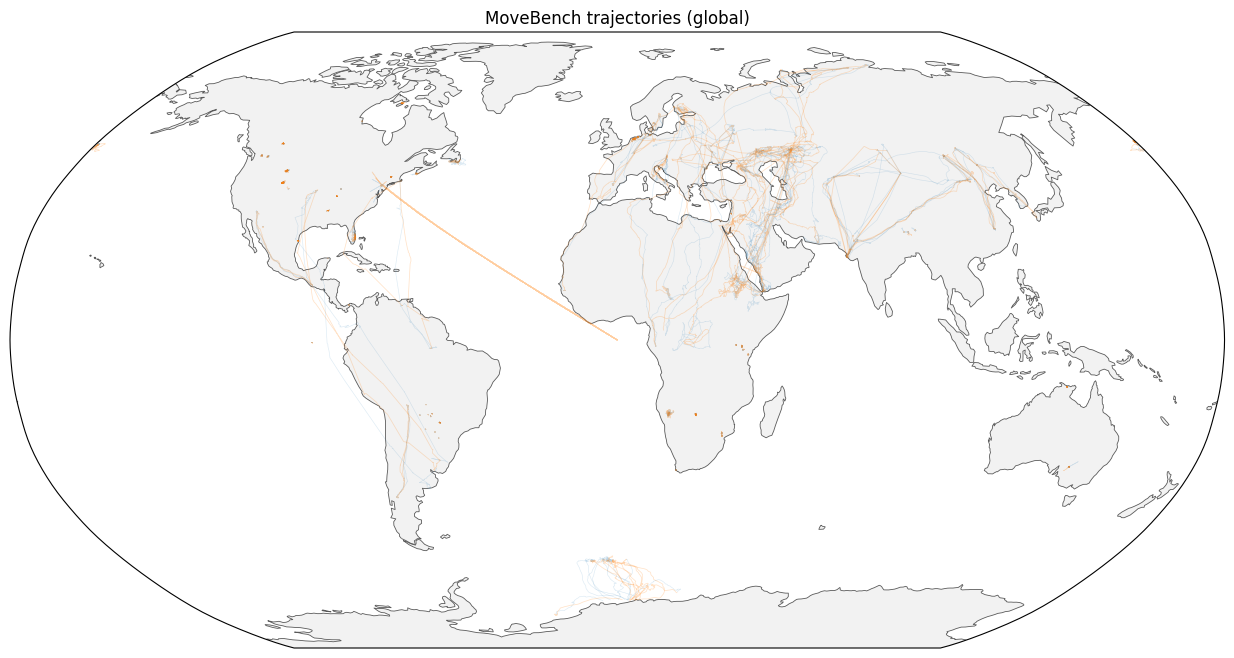

In [6]:
# --- Static global trajectory plot (saved as PNG) ---
OUT_DIR = (repo_root / 'pngs').resolve()
OUT_DIR.mkdir(parents=True, exist_ok=True)

COLOR_BY = 'split'  # 'split' or 'study'

train_color = (0.12, 0.47, 0.71, 0.15)  # RGBA
test_color = (1.00, 0.50, 0.05, 0.22)

segs_train = [r['seg'] for r in path_rows if r['split'] == 'train']
segs_test = [r['seg'] for r in path_rows if r['split'] == 'test']

if HAS_CARTOPY:
    proj = ccrs.Robinson()
    fig = plt.figure(figsize=(16, 8))
    ax = plt.axes(projection=proj)
    ax.set_global()
    ax.add_feature(cfeature.LAND.with_scale('110m'), facecolor='0.95', zorder=0)
    ax.add_feature(cfeature.OCEAN.with_scale('110m'), facecolor='white', zorder=0)
    ax.coastlines(resolution='110m', linewidth=0.6, color='0.35', zorder=1)

    if COLOR_BY == 'study':
        colors = [(*_stable_rgb(r['study_id']), 0.18 if r['split'] == 'train' else 0.28) for r in path_rows]
        lc = LineCollection([r['seg'] for r in path_rows], colors=colors, linewidths=0.45, transform=ccrs.PlateCarree())
        ax.add_collection(lc)
    else:
        if segs_train:
            lc_tr = LineCollection(segs_train, colors=[train_color], linewidths=0.45, transform=ccrs.PlateCarree())
            ax.add_collection(lc_tr)
        if segs_test:
            lc_te = LineCollection(segs_test, colors=[test_color], linewidths=0.55, transform=ccrs.PlateCarree())
            ax.add_collection(lc_te)

else:
    fig, ax = plt.subplots(figsize=(16, 8))
    ax.set_xlim(-180, 180)
    ax.set_ylim(-90, 90)
    ax.set_aspect('equal', adjustable='box')
    ax.grid(True, linewidth=0.3, color='0.85')
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')

    if COLOR_BY == 'study':
        colors = [(*_stable_rgb(r['study_id']), 0.18 if r['split'] == 'train' else 0.28) for r in path_rows]
        lc = LineCollection([r['seg'] for r in path_rows], colors=colors, linewidths=0.45)
        ax.add_collection(lc)
    else:
        if segs_train:
            lc_tr = LineCollection(segs_train, colors=[train_color], linewidths=0.45)
            ax.add_collection(lc_tr)
        if segs_test:
            lc_te = LineCollection(segs_test, colors=[test_color], linewidths=0.55)
            ax.add_collection(lc_te)

ax.set_title('MoveBench trajectories (global)')
out_path = OUT_DIR / 'global_trajectories.png'
fig.savefig(out_path, dpi=220, bbox_inches='tight')
print('wrote:', out_path)
plt.show()


wrote: /data/vision/beery/scratch/justin/movebench/pngs/global_point_density_1deg.png


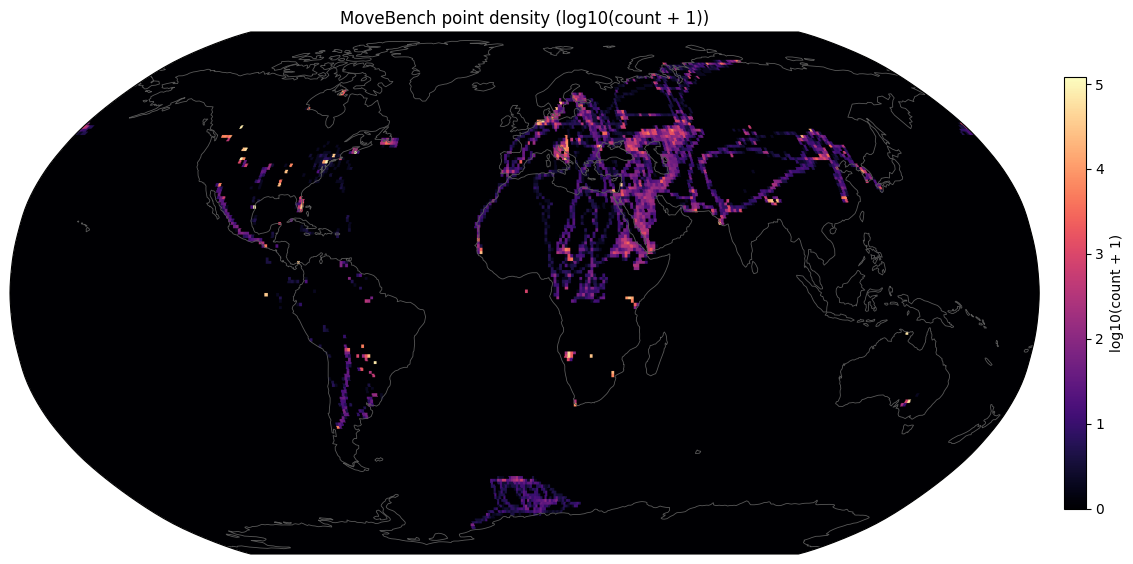

In [7]:
# --- Point density heatmap (saved as PNG) ---
OUT_DIR = (repo_root / 'pngs').resolve()
OUT_DIR.mkdir(parents=True, exist_ok=True)

lons = traj_df[LON_COL].to_numpy(dtype=np.float64, copy=False)
lats = traj_df[LAT_COL].to_numpy(dtype=np.float64, copy=False)
m = np.isfinite(lons) & np.isfinite(lats)
lons = lons[m]
lats = lats[m]

# 1-degree bins (tweak for resolution vs speed)
lon_edges = np.linspace(-180, 180, 361)
lat_edges = np.linspace(-90, 90, 181)
H, yedges, xedges = np.histogram2d(lats, lons, bins=[lat_edges, lon_edges])
Hlog = np.log10(H + 1.0)

extent = [xedges[0], xedges[-1], yedges[0], yedges[-1]]

if HAS_CARTOPY:
    fig = plt.figure(figsize=(16, 8))
    ax = plt.axes(projection=ccrs.Robinson())
    ax.set_global()
    ax.add_feature(cfeature.LAND.with_scale('110m'), facecolor='0.95', zorder=0)
    ax.add_feature(cfeature.OCEAN.with_scale('110m'), facecolor='white', zorder=0)
    ax.coastlines(resolution='110m', linewidth=0.6, color='0.35', zorder=2)
    im = ax.imshow(Hlog, extent=extent, origin='lower', transform=ccrs.PlateCarree(), cmap='magma', zorder=1)
else:
    fig, ax = plt.subplots(figsize=(16, 8))
    im = ax.imshow(Hlog, extent=extent, origin='lower', cmap='magma', aspect='auto')
    ax.set_xlim(-180, 180)
    ax.set_ylim(-90, 90)
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')

ax.set_title('MoveBench point density (log10(count + 1))')
cb = plt.colorbar(im, ax=ax, shrink=0.7, pad=0.02)
cb.set_label('log10(count + 1)')

out_path = OUT_DIR / 'global_point_density_1deg.png'
fig.savefig(out_path, dpi=220, bbox_inches='tight')
print('wrote:', out_path)
plt.show()


In [8]:
# --- Quick per-study coverage table (space/time) ---
summary = (
    traj_df.groupby("study_id")
    .agg(
        n_points=(LAT_COL, "size"),
        n_individuals=(INDIVIDUAL_COL, "nunique"),
        t_min=(TIME_COL, "min"),
        t_max=(TIME_COL, "max"),
        lat_min=(LAT_COL, "min"),
        lat_max=(LAT_COL, "max"),
        lon_min=(LON_COL, "min"),
        lon_max=(LON_COL, "max"),
    )
    .sort_values(["n_points"], ascending=False)
)

summary


,n_points,n_individuals,t_min,t_max,lat_min,lat_max,lon_min,lon_max
study_id,,,,,,,,
Bildstein_turkey_vulture,123517,4,2015-07-16 14:05:43,2021-12-28 15:00:00,-41.448170,46.234950,-113.040330,0.000000
Byholm_Caspian_tern,122180,3,2018-07-30 01:26:00,2019-12-31 23:56:00,10.485688,62.220253,-17.113190,33.528385
Mallory_American_herring_gull,119272,5,2019-05-28 16:00:00,2022-08-22 15:29:00,43.164155,44.383586,-67.763975,-64.689608
Efrat_steppe_eagle,107317,10,2018-09-20 02:37:59,2024-12-31 17:08:39,7.502053,56.482704,30.268742,71.483299
Medici_Brazilian_tapir,92192,9,2015-06-27 00:00:00,2018-10-10 13:00:00,-21.780230,-19.253489,-55.852290,-53.436950
namibia_vultures,89054,5,2008-03-28 13:50:00,2009-02-04 14:10:00,-20.407142,-18.193956,14.520998,17.020643
Guerra_Texas_gopher_tortoise__pronghorn,83714,10,2020-03-10 17:11:00,2022-03-14 23:39:00,26.006655,26.026752,-97.480011,-97.469864
Skrabal_red_kite,81121,4,2019-09-24 10:34:47,2021-10-17 12:45:52,40.621479,48.814785,11.222788,16.952385
aikens2024_pronghorn,78165,10,2019-11-11 18:00:00,2021-11-01 14:00:00,44.013641,44.640292,-109.455132,-108.097278


## Coverage visualization brainstorm

Here are additional ways to visualize **coverage** of the benchmark beyond the global trajectory map.

### Spatial coverage
- **Grid occupancy**: count points per lat/lon grid cell (e.g., 1°, 2°, 5°) and plot a world heatmap.
- **Study footprints**: bounding boxes / convex hulls per study; overlap map.
- **Per-biome/eco-region**: intersect points with biome polygons (e.g., WWF ecoregions) and show counts.
- **Coastal vs inland**: histogram of distance-to-coast / distance-to-water for observed points.

### Temporal coverage
- **Seasonality**: month-of-year heatmaps per study/individual; compare train vs test.
- **Local time-of-day**: (if timestamps in local time or convertible via timezone inference) diurnal coverage.
- **Sampling cadence**: distribution of time gaps between fixes; missingness patterns.

### Movement-behavior coverage (from trajectories only)
- **Step length vs turn angle**: 2D density (behavioral space) per study and globally.
- **Burst structure**: distribution of burst lengths (continuous segments) and gap-driven breaks.

### Environmental coverage (from rasters / point feature stores)
- **Land cover classes**: histograms of MODIS LC (`modis_lc`) at observed points; compare per study & split.
- **Vegetation**: NDVI/EVI distributions; seasonal NDVI curves; tree cover fraction (MODIS CVF).
- **Climate space**: scatter/PCA/UMAP of `bioclim` variables for observed points; compare train vs test.
- **Human influence**: histogram/quantiles of Human Impact Index (`hii`).
- **Dynamic World**: per-class probability histograms; argmax class map of visited locations.

### Dataset balance & bias
- **Geographic bias**: points per continent/country (requires polygon overlay), latitudinal bands.
- **Study contribution**: Pareto chart of points/individuals per study.
- **Train/test shift**: compare spatial density and covariate distributions between splits.


## (Optional) Coverage from point feature stores (env distributions)

If you have extracted point feature stores (SSF/iSSF), you can use them to compute land cover / vegetation / climate distributions at the **true** next-step endpoints.

This avoids re-sampling rasters yourself, and uses the same covariates the models see.

Important gotchas:
- Categorical layers (e.g. `modis_lc`) are stored as **one-hot channels** with band ids like `modis_lc.class_7` (not `modis_lc.LC_Type1`).
- If your stores were extracted with `configs/layers_local.yaml`, you will not have `modis_lc`; use `dynamic_world.*` bands instead for land-cover-ish coverage.


In [9]:
# NOTE: This section requires torch + extracted point stores.
# It is written to fail gracefully if those aren't available yet.

try:
    import torch

    from movebench.features.manifest import read_manifest
    from movebench.features.points import select_point_store_dir
except ModuleNotFoundError as e:
    print("skip env-coverage section (missing dep):", e)
    torch = None


/data/vision/beery/scratch/justin/envs/movebench/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [10]:
if torch is not None:
    from datetime import datetime

    # Match benchmark defaults (configs/benchmarks/all.yaml)
    SAMPLER = {
        'expected_type': 'parametric',
        'num_candidates': 100,
        'random_seed': 0,
        'step_multiplier': 2.0,
        'step_q': 0.95,
        'gap_q': 0.999,
        'bounds_buffer_deg': 0.01,
    }

    # MODIS LC (IGBP) class names: 0..17
    MODIS_LC_IGBP = {
        0: 'Water',
        1: 'Evergreen Needleleaf Forest',
        2: 'Evergreen Broadleaf Forest',
        3: 'Deciduous Needleleaf Forest',
        4: 'Deciduous Broadleaf Forest',
        5: 'Mixed Forests',
        6: 'Closed Shrublands',
        7: 'Open Shrublands',
        8: 'Woody Savannas',
        9: 'Savannas',
        10: 'Grasslands',
        11: 'Permanent Wetlands',
        12: 'Croplands',
        13: 'Urban and Built-Up',
        14: 'Cropland/Natural Vegetation Mosaic',
        15: 'Snow and Ice',
        16: 'Barren or Sparsely Vegetated',
        17: 'Unclassified',
    }

    DYNAMIC_WORLD_CLASSES = [
        'water',
        'trees',
        'grass',
        'flooded_vegetation',
        'crops',
        'shrub_and_scrub',
        'built',
        'bare',
        'snow_and_ice',
    ]


    def _parse_created_at(s: str):
        try:
            return datetime.fromisoformat(str(s).replace('Z', '+00:00'))
        except Exception:
            return datetime.min


    def find_point_store_dir(study: Study, *, split: str):
        """Find a point store dir for a study/split matching SAMPLER (most recent if multiple)."""
        base = study.study_dir / 'features' / 'points' / str(split)
        if not base.exists():
            return None, None

        matches = []
        for config_dir in sorted(base.iterdir()):
            if not config_dir.is_dir():
                continue
            for sampler_dir in sorted(config_dir.iterdir()):
                if not sampler_dir.is_dir():
                    continue
                mp = sampler_dir / 'manifest.json'
                fp = sampler_dir / 'features.pt'
                if not mp.exists() or not fp.exists():
                    continue
                try:
                    m = read_manifest(mp)
                except Exception:
                    continue
                s = m.sampler
                e = m.extraction
                if str(s.get('type')) != str(SAMPLER['expected_type']):
                    continue
                if int(s.get('num_candidates')) != int(SAMPLER['num_candidates']):
                    continue
                if int(s.get('random_seed')) != int(SAMPLER['random_seed']):
                    continue
                if float(s.get('step_multiplier')) != float(SAMPLER['step_multiplier']):
                    continue
                if float(s.get('step_q')) != float(SAMPLER['step_q']):
                    continue
                if float(s.get('gap_q')) != float(SAMPLER['gap_q']):
                    continue
                if float(e.get('bounds_buffer_deg')) != float(SAMPLER['bounds_buffer_deg']):
                    continue

                matches.append((sampler_dir, m))

        if not matches:
            return None, None

        matches.sort(key=lambda x: _parse_created_at(x[1].created_at))
        return matches[-1]


    def load_true_env_for_study(study_id: str, *, split: str):
        """Return (band_ids_in_order, env_true) where env_true is (N, C) at the true endpoint."""
        study = Study(study_id)
        store_dir, manifest = find_point_store_dir(study, split=split)
        if store_dir is None:
            raise FileNotFoundError('No matching point store found')

        band_ids = manifest.layer_plan.band_ids_in_order()

        tensors = torch.load(store_dir / 'features.pt', map_location='cpu')
        env = tensors['env']  # (N, C, P)
        valid = tensors['valid']  # (N, C, P)

        true_idx = int(env.shape[2] - 1)  # last index is the true endpoint
        env_true = env[:, :, true_idx]
        valid_true = valid[:, :, true_idx].to(torch.bool)

        env_true = torch.where(valid_true, env_true, torch.full_like(env_true, float('nan')))
        return band_ids, env_true.detach().cpu().numpy().astype(np.float32, copy=False)


    def land_cover_histogram(*, split: str = 'train') -> pd.DataFrame:
        counts: dict[str, int] = {}
        scheme_used: dict[str, str] = {}

        for sid in study_ids:
            try:
                band_ids, env_true = load_true_env_for_study(sid, split=split)
            except Exception as e:
                print(f'[{sid}] skip (no store or load failed): {type(e).__name__}: {e}')
                continue

            # Prefer MODIS LC if present; else fall back to Dynamic World.
            modis_idxs = [i for i, b in enumerate(band_ids) if b.startswith('modis_lc.class_')]
            if modis_idxs:
                X = env_true[:, modis_idxs]
                m = np.isfinite(X).any(axis=1)
                if m.any():
                    # One-hot; argmax recovers class id.
                    cls = np.argmax(np.nan_to_num(X[m], nan=-np.inf), axis=1).astype(int)
                    for k, v in zip(*np.unique(cls, return_counts=True)):
                        name = MODIS_LC_IGBP.get(int(k), f'class_{int(k)}')
                        counts[name] = counts.get(name, 0) + int(v)
                    scheme_used[sid] = 'modis_lc'
                continue

            dw_bands = [f'dynamic_world.{c}' for c in DYNAMIC_WORLD_CLASSES]
            if all(b in band_ids for b in dw_bands):
                idxs = [band_ids.index(b) for b in dw_bands]
                X = env_true[:, idxs]
                m = np.isfinite(X).any(axis=1)
                if m.any():
                    cls = np.argmax(np.nan_to_num(X[m], nan=-np.inf), axis=1).astype(int)
                    for k, v in zip(*np.unique(cls, return_counts=True)):
                        name = DYNAMIC_WORLD_CLASSES[int(k)]
                        counts[name] = counts.get(name, 0) + int(v)
                    scheme_used[sid] = 'dynamic_world'
                continue

            print(f'[{sid}] skip (no land-cover-like bands found)')

        out = (
            pd.DataFrame({'class': list(counts.keys()), 'count': list(counts.values())})
            .sort_values('count', ascending=False)
            .reset_index(drop=True)
        )
        print('schemes used:', pd.Series(list(scheme_used.values())).value_counts().to_dict())
        return out


    lc_hist = land_cover_histogram(split='train')
    lc_hist


[Sherub_black-necked_crane] skip (no store or load failed): FileNotFoundError: No matching point store found
schemes used: {'modis_lc': 49}


In [11]:
lc_hist

,class,count
0,Grasslands,375665
1,Croplands,105661
2,Savannas,101521
3,Unclassified,89359
4,Woody Savannas,69542
5,Open Shrublands,43641
6,Deciduous Broadleaf Forest,42561
7,Barren or Sparsely Vegetated,34220
8,Cropland/Natural Vegetation Mosaic,32908
9,Closed Shrublands,26215


<BarContainer object of 17 artists>

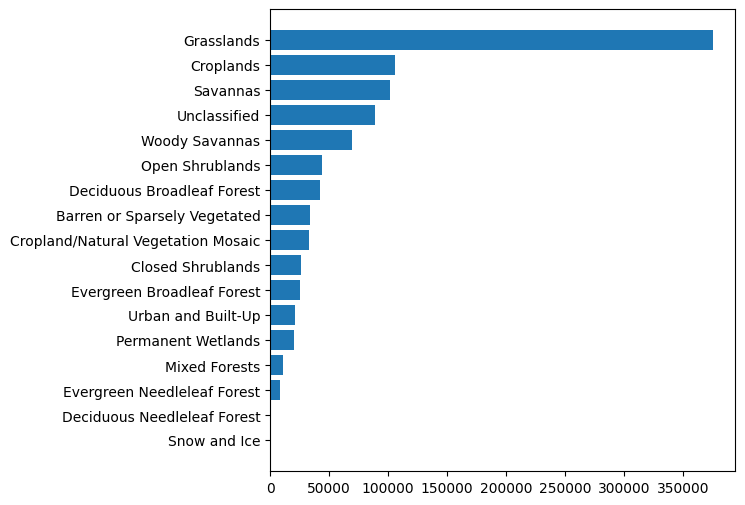

In [23]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6,6))

ax.barh(lc_hist['class'].values[::-1], lc_hist['count'].values[::-1])

----

In [24]:
from __future__ import annotations

import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

repo_root = Path.cwd().resolve()
while repo_root != repo_root.parent and not (repo_root / "movebench").exists():
    repo_root = repo_root.parent
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

_default_data_root = (repo_root / "data" / "movebench").resolve()
if "MOVEBENCH_DATA_ROOT" not in os.environ and _default_data_root.exists():
    os.environ["MOVEBENCH_DATA_ROOT"] = str(_default_data_root)

from movebench import Study
from movebench.trajectories import INDIVIDUAL_COL, LAT_COL, LON_COL, OUTLIER_COL, SET_COL, TIME_COL

TAXON_COL = "individual-taxon-canonical-name"

OUT_DIR = (repo_root / "pngs").resolve()
OUT_DIR.mkdir(parents=True, exist_ok=True)

USECOLS = [INDIVIDUAL_COL, LAT_COL, LON_COL, TIME_COL, SET_COL, OUTLIER_COL, TAXON_COL]

def load_all_trajectories() -> pd.DataFrame:
    dfs = []
    for sid in Study.list_available():
        p = Study(sid).trajectories_path
        def _use(c: str) -> bool: return c in USECOLS
        df = pd.read_csv(p, usecols=_use)
        df[TIME_COL] = pd.to_datetime(df[TIME_COL], errors="coerce")
        df = df.dropna(subset=[TIME_COL, LAT_COL, LON_COL])
        if OUTLIER_COL in df.columns:
            df = df.loc[~df[OUTLIER_COL].fillna(False).astype(bool)].copy()
        df["study_id"] = str(sid)
        dfs.append(df)
    return pd.concat(dfs, ignore_index=True)

traj_df = load_all_trajectories()
print("rows:", len(traj_df), "studies:", traj_df["study_id"].nunique(), "individuals:", traj_df[INDIVIDUAL_COL].nunique())
print("sets:", sorted(traj_df[SET_COL].dropna().unique().tolist()))


/tmp/ipykernel_2160280/2952687743.py:40: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.loc[~df[OUTLIER_COL].fillna(False).astype(bool)].copy()
/tmp/ipykernel_2160280/2952687743.py:40: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.loc[~df[OUTLIER_COL].fillna(False).astype(bool)].copy()
/tmp/ipykernel_2160280/2952687743.py:40: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set

rows: 1995772 studies: 50 individuals: 264
sets: ['test', 'train']


/tmp/ipykernel_2160280/354235144.py:22: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


wrote: /data/vision/beery/scratch/justin/movebench/pngs/coverage_study_pareto.png


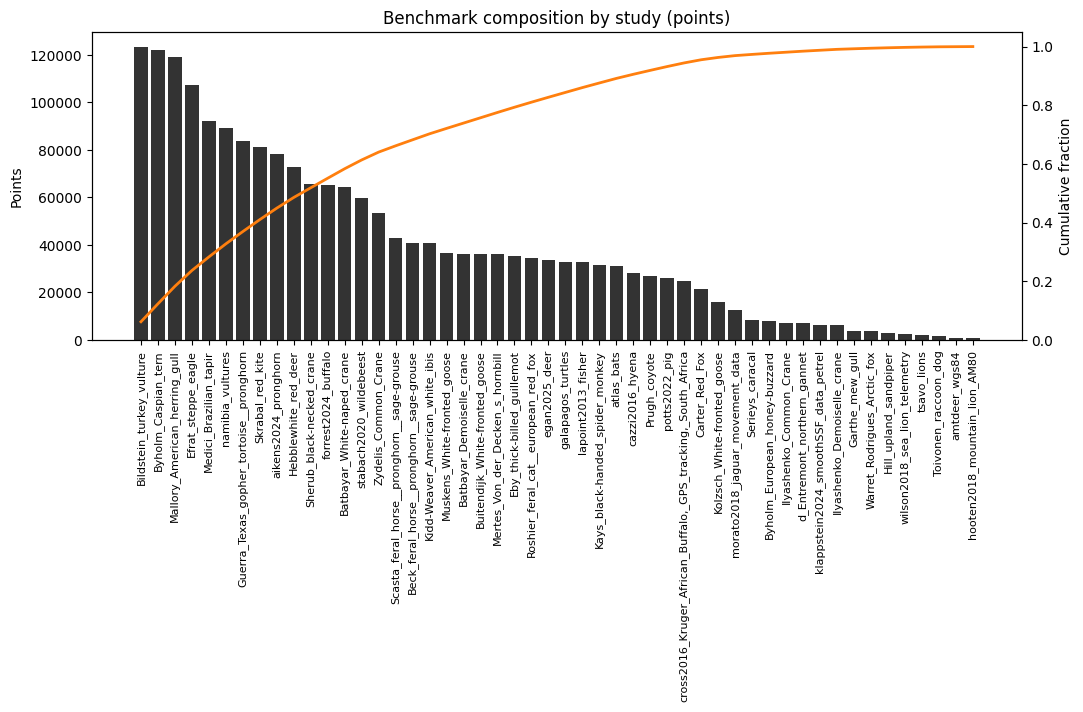

/tmp/ipykernel_2160280/354235144.py:29: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(summary.index.tolist(), rotation=90, fontsize=8)
/tmp/ipykernel_2160280/354235144.py:33: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


wrote: /data/vision/beery/scratch/justin/movebench/pngs/coverage_study_individuals.png


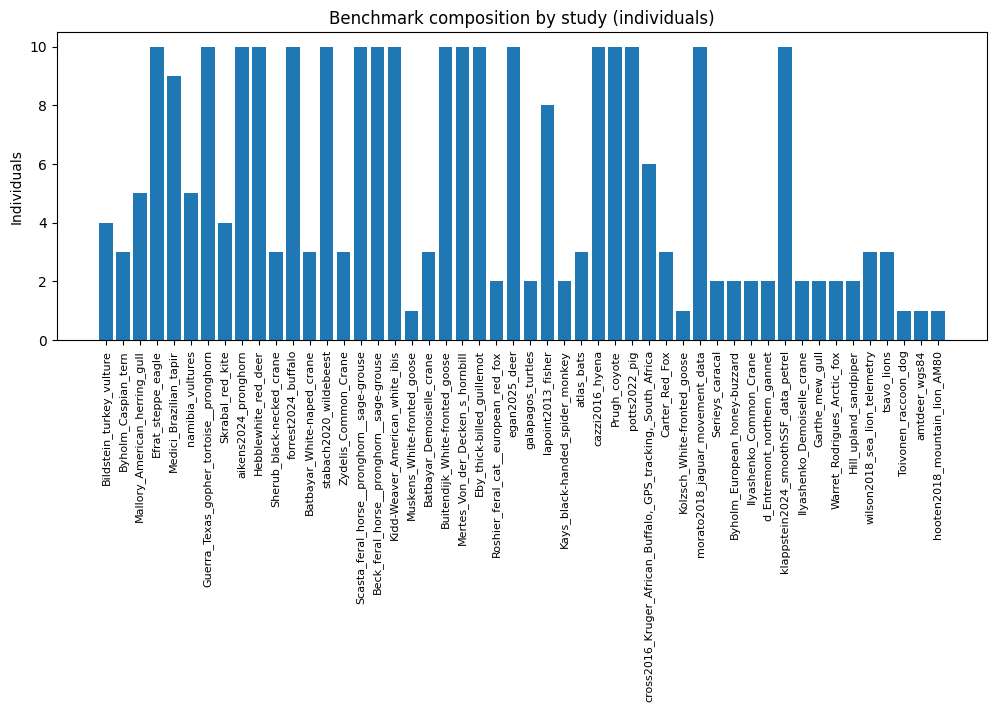

In [25]:
g = traj_df.groupby("study_id")
summary = g.agg(
    n_points=(LAT_COL, "size"),
    n_individuals=(INDIVIDUAL_COL, "nunique"),
).sort_values("n_points", ascending=False)

fig, ax1 = plt.subplots(figsize=(12, 4))
x = np.arange(len(summary))
ax1.bar(x, summary["n_points"].to_numpy(), color="0.2")
ax1.set_xticks(x)
ax1.set_xticklabels(summary.index.tolist(), rotation=90, fontsize=8)
ax1.set_ylabel("Points")
ax1.set_title("Benchmark composition by study (points)")

ax2 = ax1.twinx()
cum = summary["n_points"].cumsum() / summary["n_points"].sum()
ax2.plot(x, cum.to_numpy(), color="tab:orange", lw=2)
ax2.set_ylim(0, 1.05)
ax2.set_ylabel("Cumulative fraction")

out = OUT_DIR / "coverage_study_pareto.png"
fig.tight_layout()
fig.savefig(out, dpi=220, bbox_inches="tight")
print("wrote:", out)
plt.show()

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(summary.index, summary["n_individuals"], color="tab:blue")
ax.set_xticklabels(summary.index.tolist(), rotation=90, fontsize=8)
ax.set_ylabel("Individuals")
ax.set_title("Benchmark composition by study (individuals)")
out = OUT_DIR / "coverage_study_individuals.png"
fig.tight_layout()
fig.savefig(out, dpi=220, bbox_inches="tight")
print("wrote:", out)
plt.show()


wrote: /data/vision/beery/scratch/justin/movebench/pngs/coverage_time_gantt_by_study.png


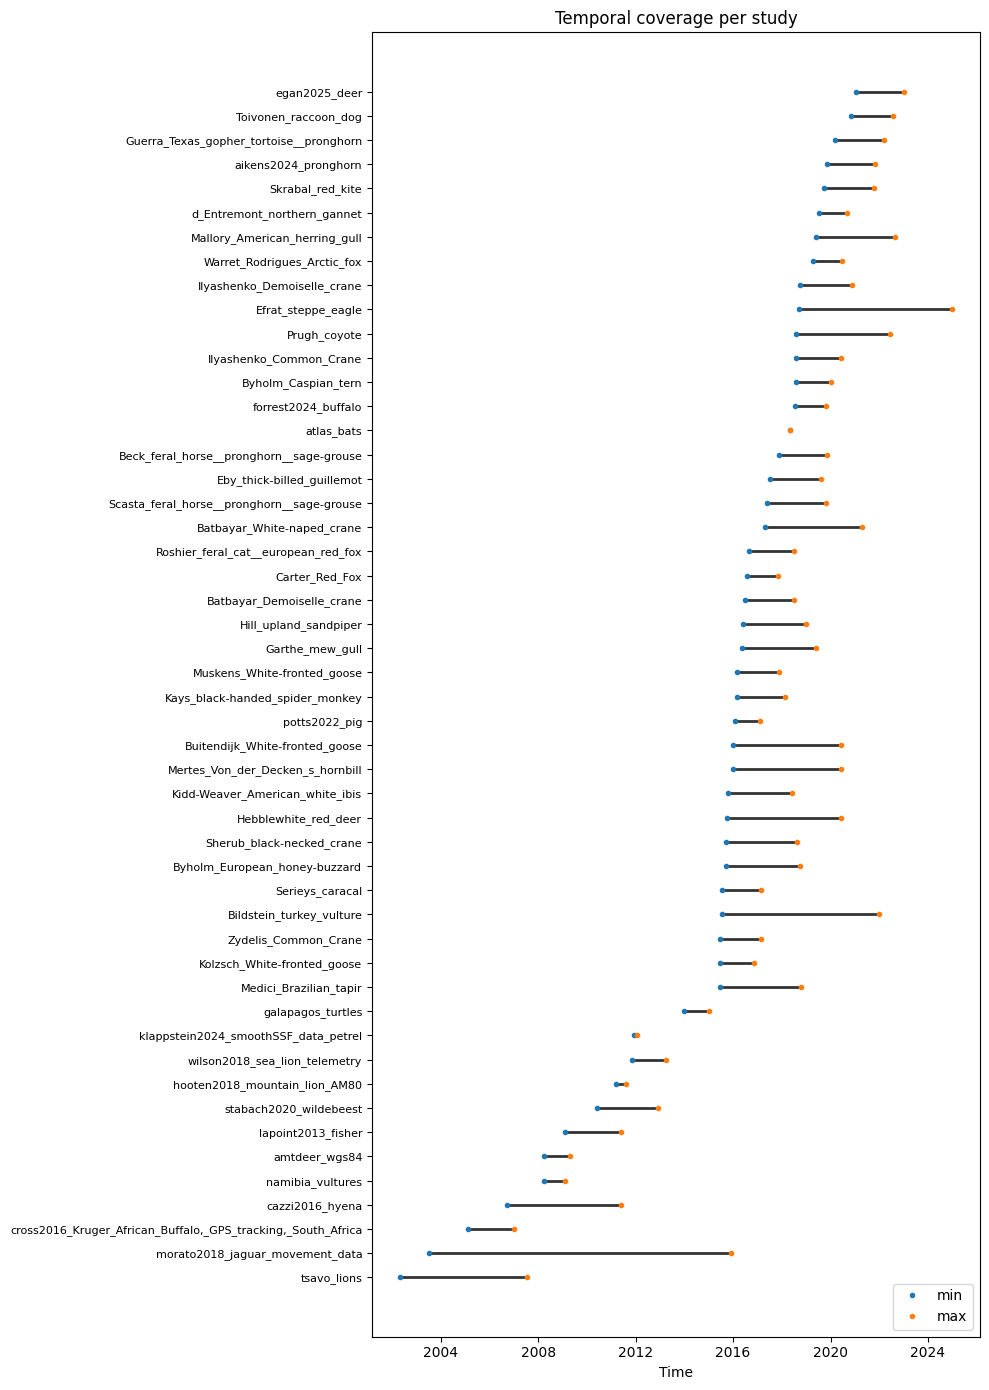

In [26]:
s = (
    traj_df.groupby("study_id")[TIME_COL]
    .agg(t_min="min", t_max="max")
    .sort_values("t_min")
)

fig, ax = plt.subplots(figsize=(10, max(4, 0.28 * len(s))))
y = np.arange(len(s))
ax.hlines(y, s["t_min"], s["t_max"], color="0.2", lw=2)
ax.plot(s["t_min"], y, "o", ms=3, color="tab:blue", label="min")
ax.plot(s["t_max"], y, "o", ms=3, color="tab:orange", label="max")
ax.set_yticks(y)
ax.set_yticklabels(s.index.tolist(), fontsize=8)
ax.set_xlabel("Time")
ax.set_title("Temporal coverage per study")
ax.legend(loc="lower right")
fig.tight_layout()
out = OUT_DIR / "coverage_time_gantt_by_study.png"
fig.savefig(out, dpi=220, bbox_inches="tight")
print("wrote:", out)
plt.show()


wrote: /data/vision/beery/scratch/justin/movebench/pngs/coverage_month_vs_lat_heatmap.png


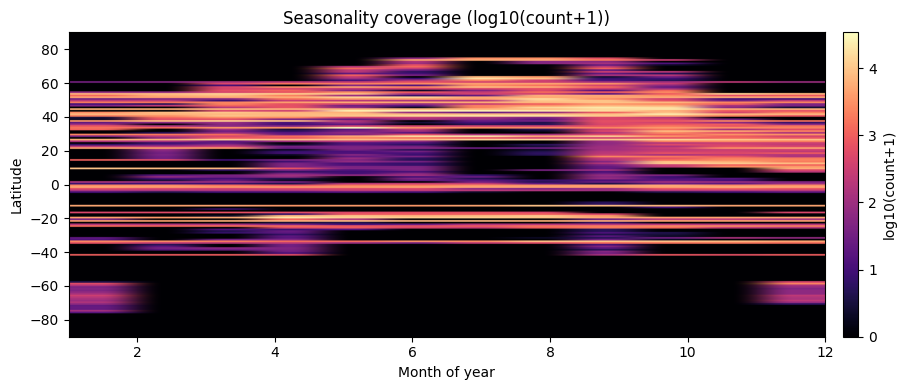

In [27]:
df = traj_df.copy()
df["month"] = df[TIME_COL].dt.month.astype("Int64")

m = df["month"].notna()
months = df.loc[m, "month"].astype(int).to_numpy()
lats = df.loc[m, LAT_COL].to_numpy(dtype=np.float64)

lat_edges = np.linspace(-90, 90, 181)          # 1° bins
mon_edges = np.arange(0.5, 12.5 + 1e-9, 1.0)   # 12 bins centered at 1..12

H, yedges, xedges = np.histogram2d(lats, months, bins=[lat_edges, mon_edges])
Hlog = np.log10(H + 1.0)

fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(
    Hlog,
    origin="lower",
    extent=[1, 12, yedges[0], yedges[-1]],
    aspect="auto",
    cmap="magma",
)
ax.set_xlabel("Month of year")
ax.set_ylabel("Latitude")
ax.set_title("Seasonality coverage (log10(count+1))")
cb = plt.colorbar(im, ax=ax, pad=0.02)
cb.set_label("log10(count+1)")
fig.tight_layout()
out = OUT_DIR / "coverage_month_vs_lat_heatmap.png"
fig.savefig(out, dpi=220, bbox_inches="tight")
print("wrote:", out)
plt.show()


wrote: /data/vision/beery/scratch/justin/movebench/pngs/coverage_spatial_occupancy_all_1deg.png


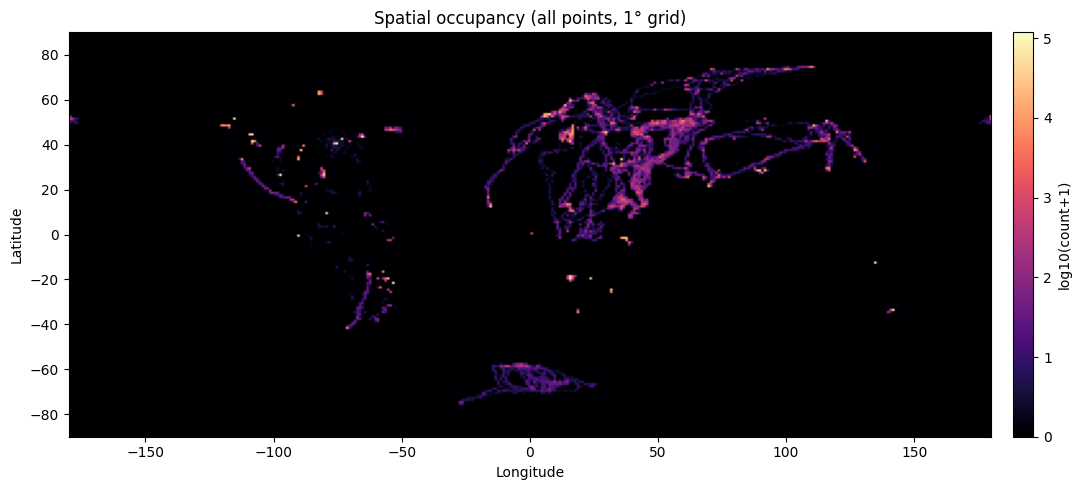

wrote: /data/vision/beery/scratch/justin/movebench/pngs/coverage_spatial_occupancy_train_1deg.png


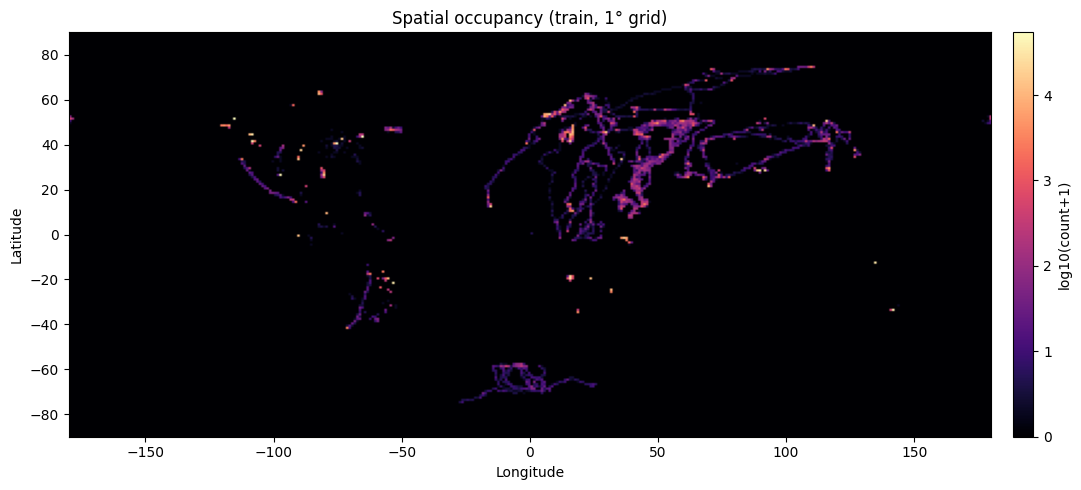

wrote: /data/vision/beery/scratch/justin/movebench/pngs/coverage_spatial_occupancy_test_1deg.png


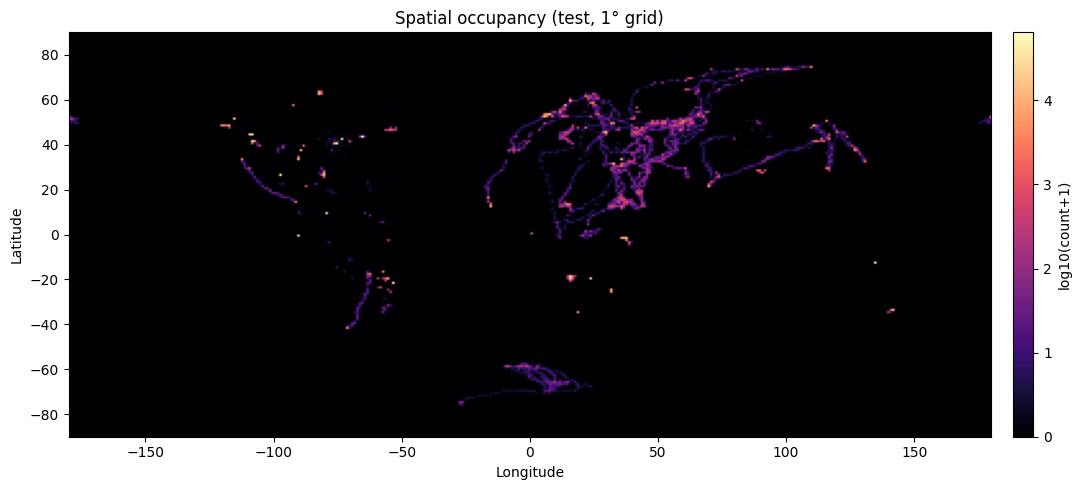

wrote: /data/vision/beery/scratch/justin/movebench/pngs/coverage_spatial_shift_train_minus_test.png


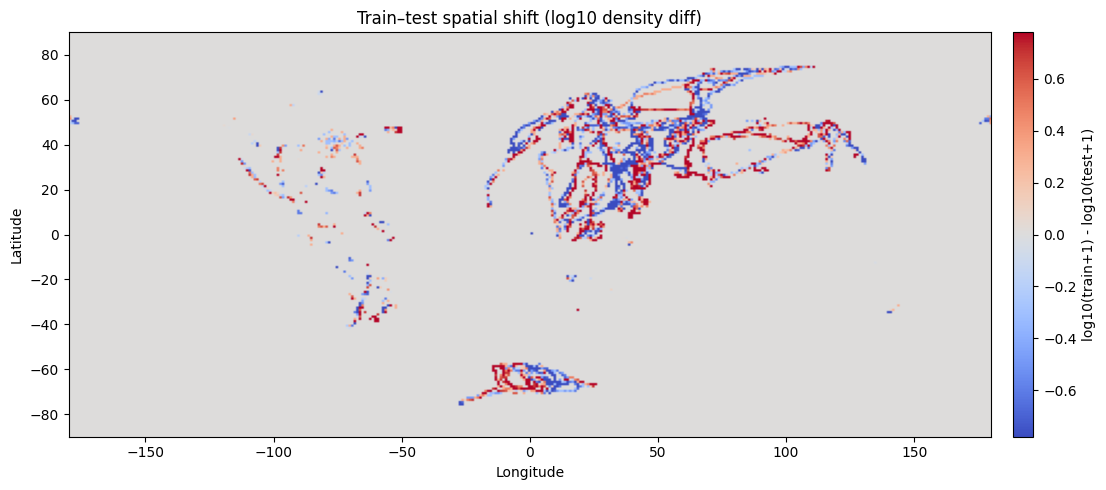

In [28]:
def occupancy_heatmap(df: pd.DataFrame, title: str, out_name: str):
    lons = df[LON_COL].to_numpy(dtype=np.float64, copy=False)
    lats = df[LAT_COL].to_numpy(dtype=np.float64, copy=False)
    m = np.isfinite(lons) & np.isfinite(lats)
    lons, lats = lons[m], lats[m]

    lon_edges = np.linspace(-180, 180, 361)
    lat_edges = np.linspace(-90, 90, 181)
    H, yedges, xedges = np.histogram2d(lats, lons, bins=[lat_edges, lon_edges])
    Hlog = np.log10(H + 1.0)

    fig, ax = plt.subplots(figsize=(12, 5))
    im = ax.imshow(
        Hlog,
        extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]],
        origin="lower",
        cmap="magma",
        aspect="auto",
    )
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_title(title)
    cb = plt.colorbar(im, ax=ax, pad=0.02)
    cb.set_label("log10(count+1)")
    fig.tight_layout()
    out = OUT_DIR / out_name
    fig.savefig(out, dpi=220, bbox_inches="tight")
    print("wrote:", out)
    plt.show()

occupancy_heatmap(traj_df, "Spatial occupancy (all points, 1° grid)", "coverage_spatial_occupancy_all_1deg.png")
occupancy_heatmap(traj_df[traj_df[SET_COL] == "train"], "Spatial occupancy (train, 1° grid)", "coverage_spatial_occupancy_train_1deg.png")
occupancy_heatmap(traj_df[traj_df[SET_COL] == "test"], "Spatial occupancy (test, 1° grid)", "coverage_spatial_occupancy_test_1deg.png")

# train-test log-density difference
def log_density(df: pd.DataFrame):
    lons = df[LON_COL].to_numpy(dtype=np.float64, copy=False)
    lats = df[LAT_COL].to_numpy(dtype=np.float64, copy=False)
    m = np.isfinite(lons) & np.isfinite(lats)
    lons, lats = lons[m], lats[m]
    lon_edges = np.linspace(-180, 180, 361)
    lat_edges = np.linspace(-90, 90, 181)
    H, yedges, xedges = np.histogram2d(lats, lons, bins=[lat_edges, lon_edges])
    return np.log10(H + 1.0), (xedges, yedges)

Htr, (xedges, yedges) = log_density(traj_df[traj_df[SET_COL] == "train"])
Hte, _ = log_density(traj_df[traj_df[SET_COL] == "test"])
D = Htr - Hte

fig, ax = plt.subplots(figsize=(12, 5))
im = ax.imshow(
    D,
    extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]],
    origin="lower",
    cmap="coolwarm",
    vmin=-np.nanpercentile(abs(D), 98),
    vmax=np.nanpercentile(abs(D), 98),
    aspect="auto",
)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Train–test spatial shift (log10 density diff)")
cb = plt.colorbar(im, ax=ax, pad=0.02)
cb.set_label("log10(train+1) - log10(test+1)")
fig.tight_layout()
out = OUT_DIR / "coverage_spatial_shift_train_minus_test.png"
fig.savefig(out, dpi=220, bbox_inches="tight")
print("wrote:", out)
plt.show()


wrote: /data/vision/beery/scratch/justin/movebench/pngs/coverage_sampling_dt_hist.png


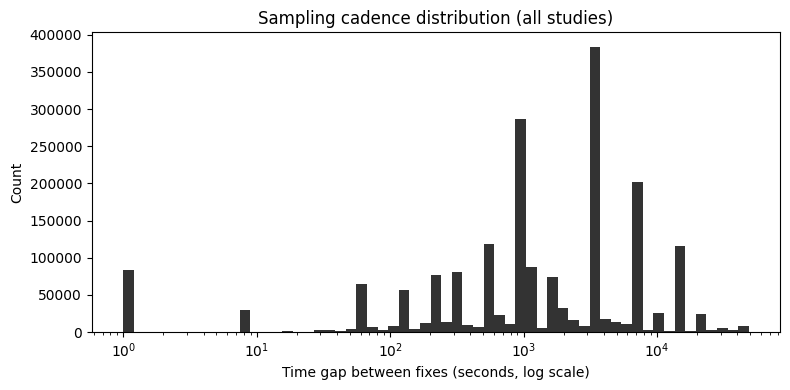

/tmp/ipykernel_2160280/1813268776.py:29: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(med.index.tolist(), rotation=90, fontsize=8)
/tmp/ipykernel_2160280/1813268776.py:32: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


wrote: /data/vision/beery/scratch/justin/movebench/pngs/coverage_sampling_dt_median_by_study.png


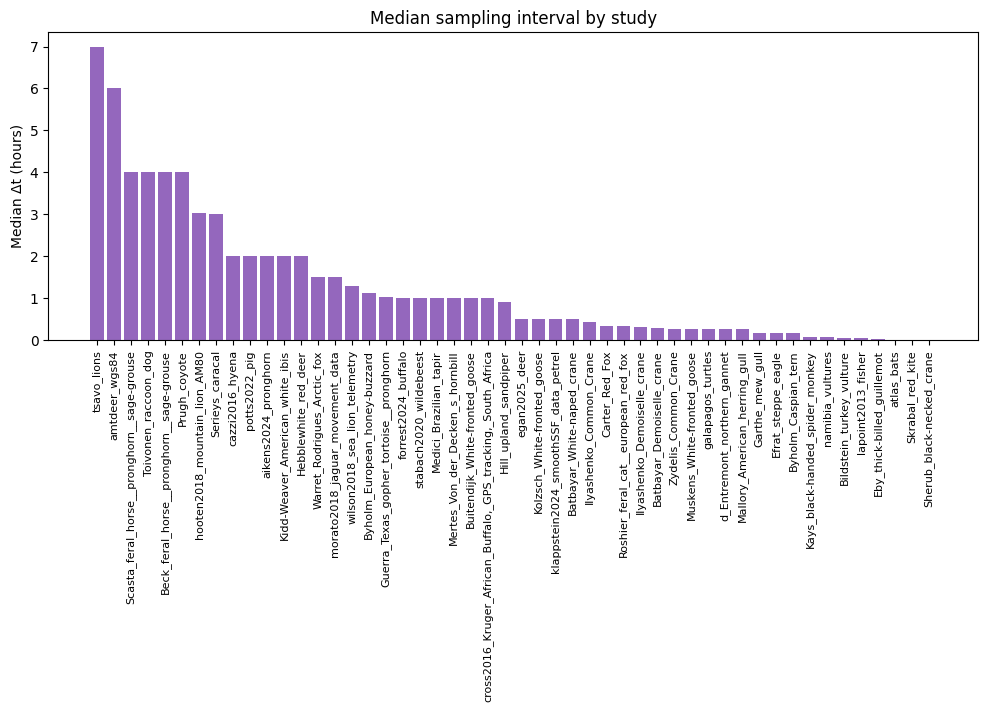

In [29]:
df = traj_df.sort_values([ "study_id", INDIVIDUAL_COL, TIME_COL ]).copy()
dt = df.groupby(["study_id", INDIVIDUAL_COL])[TIME_COL].diff().dt.total_seconds()
dt = dt.to_numpy(dtype=np.float64)
dt = dt[np.isfinite(dt) & (dt > 0)]

fig, ax = plt.subplots(figsize=(8, 4))
bins = np.logspace(np.log10(1), np.log10(np.percentile(dt, 99.5)), 60)
ax.hist(dt, bins=bins, color="0.2")
ax.set_xscale("log")
ax.set_xlabel("Time gap between fixes (seconds, log scale)")
ax.set_ylabel("Count")
ax.set_title("Sampling cadence distribution (all studies)")
fig.tight_layout()
out = OUT_DIR / "coverage_sampling_dt_hist.png"
fig.savefig(out, dpi=220, bbox_inches="tight")
print("wrote:", out)
plt.show()

# per-study median dt (hours)
med = (
    traj_df.sort_values(["study_id", INDIVIDUAL_COL, TIME_COL])
    .groupby(["study_id", INDIVIDUAL_COL])[TIME_COL].diff().dt.total_seconds()
    .groupby(traj_df["study_id"])
    .median() / 3600.0
).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(med.index, med.to_numpy(), color="tab:purple")
ax.set_xticklabels(med.index.tolist(), rotation=90, fontsize=8)
ax.set_ylabel("Median Δt (hours)")
ax.set_title("Median sampling interval by study")
fig.tight_layout()
out = OUT_DIR / "coverage_sampling_dt_median_by_study.png"
fig.savefig(out, dpi=220, bbox_inches="tight")
print("wrote:", out)
plt.show()


wrote: /data/vision/beery/scratch/justin/movebench/pngs/coverage_behavior_step_vs_turn_density.png


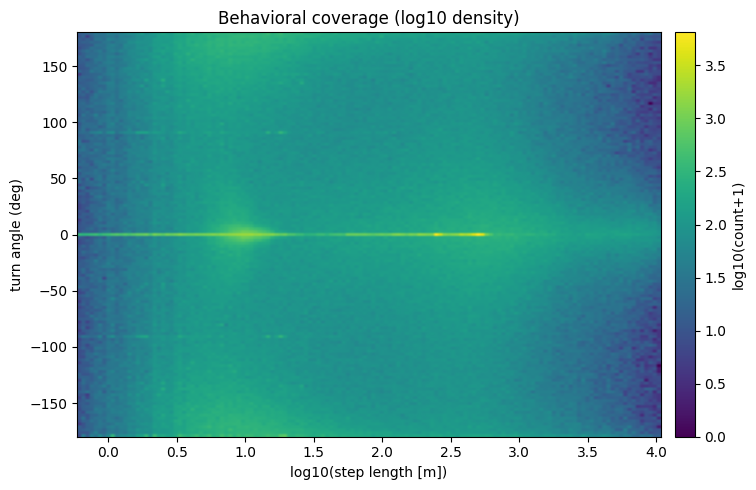

In [30]:
df = traj_df.sort_values(["study_id", INDIVIDUAL_COL, TIME_COL]).copy()
g = df.groupby(["study_id", INDIVIDUAL_COL])

lat = df[LAT_COL].to_numpy(dtype=np.float64, copy=False)
lon = df[LON_COL].to_numpy(dtype=np.float64, copy=False)

lat_prev = g[LAT_COL].shift(1).to_numpy(dtype=np.float64)
lon_prev = g[LON_COL].shift(1).to_numpy(dtype=np.float64)
lat_next = g[LAT_COL].shift(-1).to_numpy(dtype=np.float64)
lon_next = g[LON_COL].shift(-1).to_numpy(dtype=np.float64)

step = geodesic_distance_m(lat_prev, lon_prev, lat, lon)
b1 = arrival_bearing_rad(lat_prev, lon_prev, lat, lon)
b2 = bearing_rad(lat, lon, lat_next, lon_next)
turn = (b2 - b1 + np.pi) % (2*np.pi) - np.pi  # [-pi, pi]

m = np.isfinite(step) & np.isfinite(turn) & (step > 0)
step = step[m]
turn = turn[m]

# 2D density histogram (log)
x = np.log10(step)
y = np.rad2deg(turn)

xb = np.linspace(np.percentile(x, 1), np.percentile(x, 99), 140)
yb = np.linspace(-180, 180, 140)
H, xe, ye = np.histogram2d(x, y, bins=[xb, yb])
Hlog = np.log10(H + 1.0)

fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(
    Hlog.T,
    origin="lower",
    extent=[xe[0], xe[-1], ye[0], ye[-1]],
    aspect="auto",
    cmap="viridis",
)
ax.set_xlabel("log10(step length [m])")
ax.set_ylabel("turn angle (deg)")
ax.set_title("Behavioral coverage (log10 density)")
cb = plt.colorbar(im, ax=ax, pad=0.02)
cb.set_label("log10(count+1)")
fig.tight_layout()
out = OUT_DIR / "coverage_behavior_step_vs_turn_density.png"
fig.savefig(out, dpi=220, bbox_inches="tight")
print("wrote:", out)
plt.show()


wrote: /data/vision/beery/scratch/justin/movebench/pngs/coverage_taxa_top25_points.png


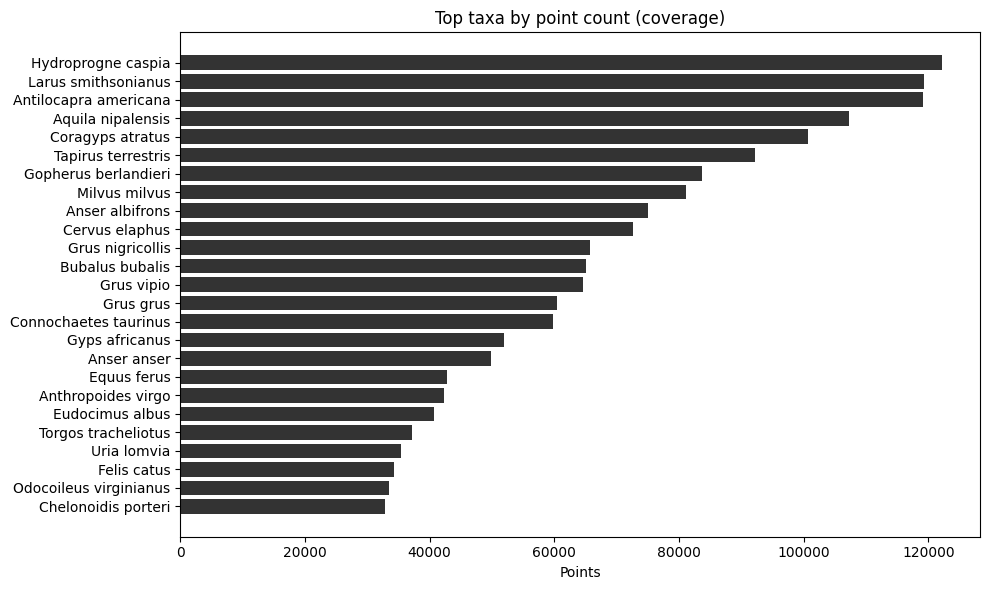

In [31]:
if TAXON_COL in traj_df.columns:
    tax = traj_df[TAXON_COL].fillna("(missing)").astype(str)
    top = tax.value_counts().head(25)

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(top.index[::-1], top.to_numpy()[::-1], color="0.2")
    ax.set_xlabel("Points")
    ax.set_title("Top taxa by point count (coverage)")
    fig.tight_layout()
    out = OUT_DIR / "coverage_taxa_top25_points.png"
    fig.savefig(out, dpi=220, bbox_inches="tight")
    print("wrote:", out)
    plt.show()
else:
    print("skip: TAXON_COL not in traj_df")


In [35]:
from __future__ import annotations

from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TAXON_COL = "individual-taxon-canonical-name"
CACHE = OUT_DIR / "taxonomy_cache.csv"  # uses OUT_DIR from your earlier setup

def _clean_name(name: str) -> str:
    name = str(name).strip()
    if not name or name.lower() in {"nan", "none"}:
        return ""
    name = re.sub(r"\s+", " ", name)
    # Keep just Genus species when possible
    parts = name.split(" ")
    if len(parts) >= 2:
        return f"{parts[0]} {parts[1]}"
    return name

def _load_cache(path: Path) -> pd.DataFrame:
    if path.exists():
        return pd.read_csv(path)
    return pd.DataFrame(columns=["taxon_clean", "taxid", "class", "order", "family"])

def _save_cache(path: Path, df: pd.DataFrame) -> None:
    df = df.drop_duplicates(subset=["taxon_clean"]).sort_values("taxon_clean")
    df.to_csv(path, index=False)

def add_taxonomy_groups(df: pd.DataFrame, taxon_col: str = TAXON_COL) -> pd.DataFrame:
    try:
        from ete3 import NCBITaxa
    except ModuleNotFoundError as e:
        raise ModuleNotFoundError("Install ete3 first: pip install ete3") from e

    out = df.copy()
    out["taxon_clean"] = out[taxon_col].fillna("").map(_clean_name)

    cache = _load_cache(CACHE)
    known = set(cache["taxon_clean"].astype(str).tolist())
    todo = sorted(set(out["taxon_clean"].tolist()) - known - {""})

    ncbi = NCBITaxa()

    # If you haven't downloaded the DB yet, you may need:
    # ncbi.update_taxonomy_database()

    new_rows = []
    for name in todo:
        taxid = None
        cls = ord_ = fam = None

        try:
            name2taxid = ncbi.get_name_translator([name])
            taxids = name2taxid.get(name, [])
            if taxids:
                taxid = int(taxids[0])
                lineage = ncbi.get_lineage(taxid)
                ranks = ncbi.get_rank(lineage)          # taxid -> rank
                names = ncbi.get_taxid_translator(lineage)  # taxid -> scientific name

                def pick(rank: str):
                    ids = [tid for tid in lineage if ranks.get(tid) == rank]
                    return names.get(ids[0]) if ids else None

                cls = pick("class")
                ord_ = pick("order")
                fam = pick("family")
        except Exception:
            pass

        new_rows.append(
            {"taxon_clean": name, "taxid": taxid, "class": cls, "order": ord_, "family": fam}
        )

    if new_rows:
        cache = pd.concat([cache, pd.DataFrame(new_rows)], ignore_index=True)
        _save_cache(CACHE, cache)
        print(f"updated taxonomy cache: {CACHE} (+{len(new_rows)} taxa)")

    out = out.merge(cache, on="taxon_clean", how="left")
    out["class"] = out["class"].fillna("Unknown")
    out["order"] = out["order"].fillna("Unknown")
    out["family"] = out["family"].fillna("Unknown")
    return out

traj_tax = add_taxonomy_groups(traj_df)
traj_tax[["study_id", TAXON_COL, "taxon_clean", "class", "order", "family"]].head()


NCBI database not present yet (first time used?)
Done. Parsing...


Loading node names...
2725989 names loaded.
428733 synonyms loaded.
Loading nodes...
2725989 nodes loaded.
Linking nodes...
Tree is loaded.
Updating database: /tmp/home/kayj/.etetoolkit/taxa.sqlite ...
 2725000 generating entries... 

Inserting synonyms:      35000 


Uploading to /tmp/home/kayj/.etetoolkit/taxa.sqlite



Inserting synonyms:      425000 

Inserting taxids:       60000  

Inserting taxids:       2725000 


updated taxonomy cache: /data/vision/beery/scratch/justin/movebench/pngs/taxonomy_cache.csv (+45 taxa)


,study_id,individual-taxon-canonical-name,taxon_clean,class,order,family
0,Batbayar_Demoiselle_crane,Anthropoides virgo,Anthropoides virgo,Aves,Gruiformes,Gruidae
1,Batbayar_Demoiselle_crane,Anthropoides virgo,Anthropoides virgo,Aves,Gruiformes,Gruidae
2,Batbayar_Demoiselle_crane,Anthropoides virgo,Anthropoides virgo,Aves,Gruiformes,Gruidae
3,Batbayar_Demoiselle_crane,Anthropoides virgo,Anthropoides virgo,Aves,Gruiformes,Gruidae
4,Batbayar_Demoiselle_crane,Anthropoides virgo,Anthropoides virgo,Aves,Gruiformes,Gruidae


wrote: /data/vision/beery/scratch/justin/movebench/pngs/coverage_tax_class_points.png


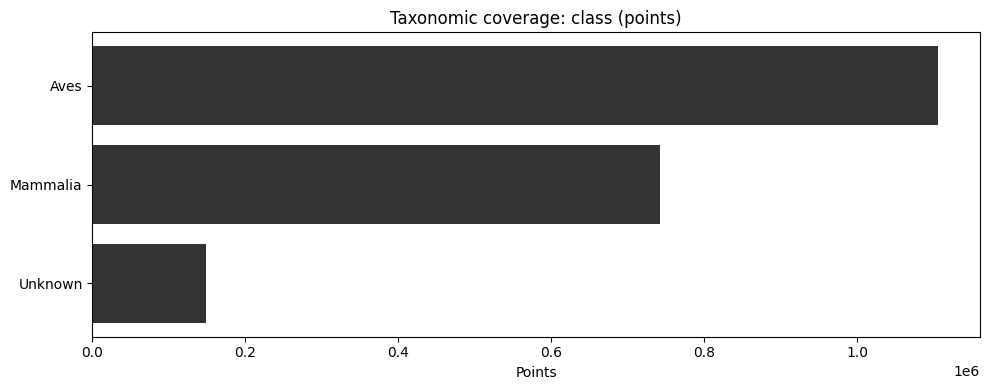

wrote: /data/vision/beery/scratch/justin/movebench/pngs/coverage_tax_order_points.png


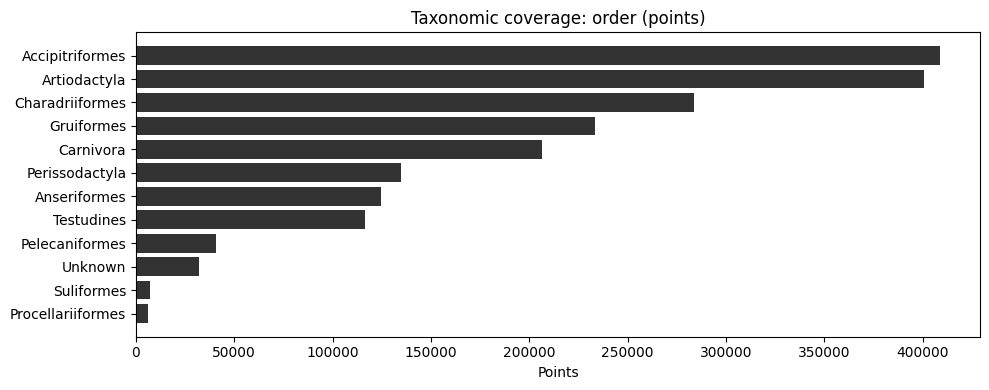

wrote: /data/vision/beery/scratch/justin/movebench/pngs/coverage_tax_family_points.png


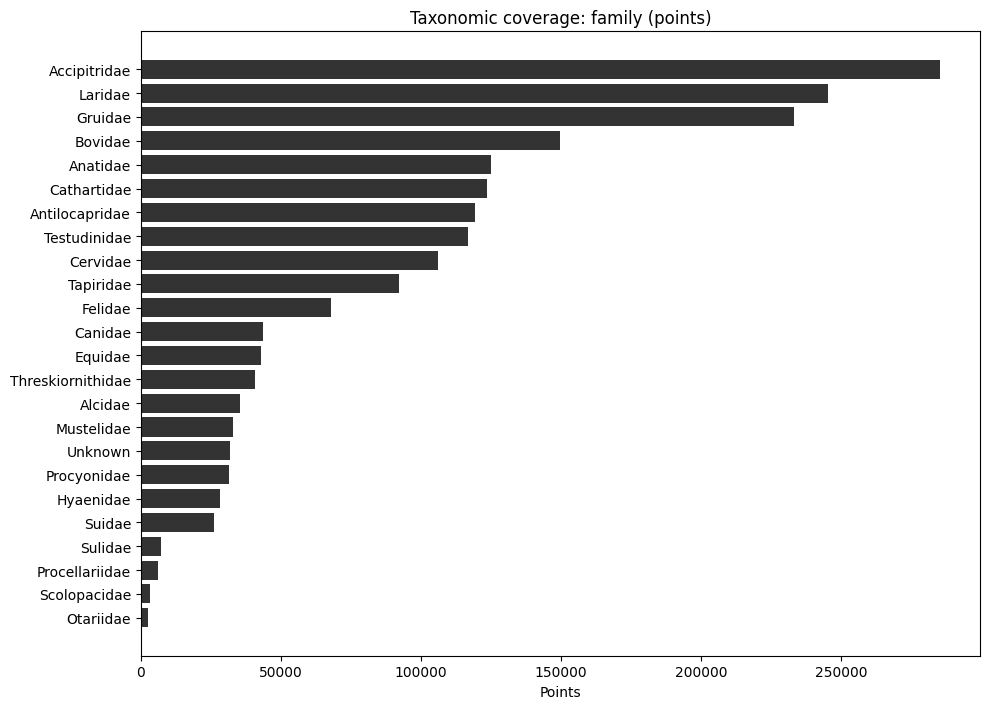

In [36]:
def bar_counts(series: pd.Series, title: str, out_name: str, top_k: int = 25):
    vc = series.value_counts().head(top_k)
    fig, ax = plt.subplots(figsize=(10, max(4, 0.3 * len(vc))))
    ax.barh(vc.index[::-1], vc.to_numpy()[::-1], color="0.2")
    ax.set_xlabel("Points")
    ax.set_title(title)
    fig.tight_layout()
    out = OUT_DIR / out_name
    fig.savefig(out, dpi=220, bbox_inches="tight")
    print("wrote:", out)
    plt.show()

bar_counts(traj_tax["class"],  "Taxonomic coverage: class (points)",  "coverage_tax_class_points.png",  top_k=50)
bar_counts(traj_tax["order"],  "Taxonomic coverage: order (points)",  "coverage_tax_order_points.png",  top_k=40)
bar_counts(traj_tax["family"], "Taxonomic coverage: family (points)", "coverage_tax_family_points.png", top_k=40)
